# KAN-4 — Análise exploratória (EDA) vs. inadimplência

Projeto CIN0144 · Tema 8: Praso — Previsão de Inadimplência.

Objetivo: entender como cada variável se relaciona com a inadimplência antes de modelar, testando hipóteses registradas antes de olhar os dados.

**Seções:** 0. Hipóteses · 1. Variáveis contínuas e em faixas · 2. Variáveis categóricas e binárias · 3. CNAE e credores da Serasa · 4. Histórico de pedidos · 5. Conclusões

> Só mostramos agregados: os dados da Praso são confidenciais.

## 0. Hipóteses (escritas antes de olhar os dados)

> Estas hipóteses foram registradas **antes** de qualquer contato com os dados, como pede o KAN-4. A EDA vai testar cada uma e marcá-la como **confirmada**, **refutada** ou **inconclusiva**. O texto abaixo não será alterado depois dos resultados.
>
> **Referência:** "acima/abaixo da média" compara com a taxa de inadimplência geral da base, que ainda vamos medir. **Direção** indica como o risco de inadimplência (`inadimplente = 1`) deve variar com a variável.

**H1 — Idade do CNPJ**
- **Expectativa:** clientes com CNPJ mais novo no momento do cadastro têm inadimplência acima da média. O efeito deve ser mais forte no primeiro ano de empresa. CNPJs abertos poucos dias antes do cadastro devem ter risco ainda maior.
- **Direção:** negativa (mais idade, menos risco), não linear e estabilizando depois de alguns anos.
- **Justificativa:** a maioria dos pequenos negócios que fecham fecha nos primeiros anos, e um CNPJ aberto pouco antes do cadastro pode ser uma empresa criada só para conseguir crédito.

**H2 — Capital social**
- **Expectativa:** capital social maior vem com inadimplência menor, mas o sinal é fraco e aparece sobretudo nos valores mais altos.
- **Direção:** negativa e fraca.
- **Justificativa:** o capital social é declarado pela própria empresa e costuma ser simbólico nas pequenas (ex.: R$ 1.000), então só valores altos indicam de fato mais reserva financeira.

**H3 — Natureza jurídica**
- **Expectativa:** Empresário Individual (213-5, que inclui o MEI) tem inadimplência acima de Sociedade Empresária Limitada (206-2).
- **Direção:** Empresário Individual com mais risco que LTDA.
- **Justificativa:** no empresário individual as contas da pessoa física e da empresa se misturam e a gestão é mínima, o que deixa o negócio mais exposto a apertos de caixa.

**H4 — Negativações e protestos na Serasa**
- **Expectativa:** clientes com ao menos uma negativação ou um protesto têm inadimplência acima da média, e o risco cresce com a quantidade. O protesto deve ser um sinal mais forte que a negativação.
- **Direção:** positiva, sempre crescente, mas crescendo menos a partir de algumas ocorrências.
- **Justificativa:** quem já deixou de pagar é quem mais tende a deixar de pagar de novo, e o protesto exige um passo formal em cartório, o que indica dívidas mais graves ou mais antigas.

**H5 — Sócio negativado**
- **Expectativa:** clientes com `serasa_socio_tem_negativacao = 1` têm inadimplência acima da média. O efeito deve ser maior no Empresário Individual do que na LTDA.
- **Direção:** positiva, com interação com a natureza jurídica.
- **Justificativa:** numa empresa pequena, o comportamento de crédito do dono é praticamente o da empresa, sobretudo quando o patrimônio é o mesmo.

**H6 — Credores (quantidade e segmento)**
- **Expectativa:** clientes sem credores (campo nulo) têm a menor inadimplência, e o risco cresce com o número de credores. A lista tem no máximo 5 itens, então a contagem trava em 5. Dever a segmentos de crédito comercial ou financeiro (como fornecedores e financeiras) deve pesar mais do que dever a serviços como água, luz ou telefonia.
- **Direção:** positiva para a quantidade de credores. Por segmento, o efeito deve variar sem uma ordem definida.
- **Justificativa:** vários credores indicam um caixa comprometido em várias frentes, e quem já deixou de pagar um fornecedor tende a repetir isso com a Praso, que ocupa a mesma posição na fila de pagamentos.

**H7 — Presença no iFood e no Google Maps**
- **Expectativa:** clientes presentes no iFood e/ou no Google Maps têm inadimplência abaixo dos ausentes. Estar nos dois deve ser o melhor cenário.
- **Direção:** negativa (estar presente reduz o risco). Os nulos carregam informação e viram indicadores de ausência, sem preenchimento por média.
- **Justificativa:** estar listado mostra que o negócio funciona de fato, com ponto físico ou vendas que dá para conferir, o que reduz o risco de empresa de fachada ou prestes a fechar.

**H8 — Reputação digital (avaliações e website)**
- **Expectativa:** entre os clientes presentes, mais avaliações (no iFood e no Maps) e ter website vêm com inadimplência menor. Nota baixa no Maps (ex.: abaixo de 3,5) vem com inadimplência maior. Uma nota alta com poucas avaliações diz pouco. Também é preciso checar se a nota 0 significa "sem avaliação".
- **Direção:** mais avaliações e ter website reduzem o risco. Nota mais alta também reduz, mas de forma fraca.
- **Justificativa:** a quantidade de avaliações indica volume de vendas e tempo de operação, e a nota reflete a qualidade da gestão, embora seja instável quando há poucas avaliações.

**H9 — Faixa de preço no iFood**
- **Expectativa:** as faixas mais altas ($$$$ e $$$$$) têm inadimplência menor que as faixas baixas ($ e $$).
- **Direção:** negativa e fraca.
- **Justificativa:** estabelecimentos de preço mais alto tendem a ter margem maior e clientes menos afetados por crises, o que deixa mais folga de caixa para pagar os boletos.

**H10 — Segmento do cliente e CNAE**
- **Expectativa:** a inadimplência varia bastante entre segmentos e entre grupos de atividade econômica (CNAE). Os níveis mais amplos da hierarquia do CNAE (divisão e grupo) devem captar a maior parte dessa diferença, com menos ruído que o código completo.
- **Direção:** varia por categoria, sem uma ordem definida.
- **Justificativa:** as atividades diferem em margem, sazonalidade e taxa de fechamento, e agrupar pela hierarquia evita categorias pequenas demais, cuja taxa muda muito por acaso.

**H11 — Fonte de aquisição**
- **Expectativa:** a inadimplência difere entre as Fontes 1 a 5, com pelo menos uma fonte claramente acima da média. Canais baseados em incentivo ou prospecção ativa devem ficar acima de canais orgânicos ou por indicação.
- **Direção:** varia por fonte, sem uma ordem definida.
- **Justificativa:** canais que atraem clientes com desconto ou prazo tendem a atrair justamente os clientes mais arriscados (seleção adversa), enquanto a indicação traz clientes já filtrados por quem conhece o negócio.

**H12 — Município (capital vs. interior)**
- **Expectativa:** clientes do interior do CE têm inadimplência acima dos de Fortaleza e da região metropolitana. Confiança baixa nesta hipótese.
- **Direção:** mais risco no interior que na capital.
- **Justificativa:** no interior a renda é menor e mais sazonal, cobrar pessoalmente custa mais e a Serasa tem menos informação sobre os clientes, então o risco aparece menos no cadastro.

**H13 — Frequência e recorrência de pedidos**
- **Expectativa:** clientes com mais pedidos anteriores e compra recorrente têm inadimplência menor. Primeiras compras, e pedidos muito acima do valor habitual do cliente (sobretudo logo no início), têm inadimplência maior.
- **Direção:** mais pedidos reduzem o risco; pedidos maiores que o habitual aumentam o risco.
- **Justificativa:** quem volta a comprar já mostrou que paga e depende da relação, enquanto um pedido grande e fora do padrão é o golpe clássico de comprar e sumir (*bust-out*).

**H14 — Atraso histórico nos pedidos**
- **Expectativa:** clientes que já atrasaram pedidos anteriores, mesmo que tenham pago depois, têm inadimplência bem acima da média. O risco cresce com o atraso médio e o atraso máximo, e com a piora dos atrasos recentes.
- **Direção:** positiva.
- **Justificativa:** o atraso costuma vir antes do calote, e uma piora recente mostra o caixa se deteriorando antes de isso aparecer na Serasa.

---

**Cuidados para testar as hipóteses**
- **Vazamento de informação:** os indicadores de pedidos (H13 e H14) usam apenas pedidos com data de entrega anterior ao pedido avaliado. O atraso do próprio pedido provavelmente define o alvo e não pode entrar como variável.
- **Nulos que carregam informação:** em iFood, Maps e `serasa_credores`, o nulo significa ausência. Vamos tratá-lo como uma categoria própria ou um indicador, e não preencher com a média.
- **Categorias pequenas:** em municípios, CNAE, segmentos e fontes, só tiramos conclusões com volume mínimo e intervalo de confiança. Categorias raras serão agrupadas antes de comparar taxas.

## Setup

In [1]:
import sys
import unicodedata
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

from src import dados

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
FIG = Path("../reports/figures")
FIG.mkdir(parents=True, exist_ok=True)

clientes, pedidos = dados.carregar_dados_limpos()
TAXA_GERAL = clientes["inadimplente"].mean()
print(f"clientes: {clientes.shape} | pedidos: {pedidos.shape} | taxa geral: {TAXA_GERAL:.1%}")


def taxa_por_grupo(df, col, alvo="inadimplente", min_n=30):
    """Taxa de inadimplência por grupo, com IC 95% (Wilson) e flag de baixa representatividade."""
    g = df.groupby(col, dropna=False, observed=True)[alvo].agg(n="size", inadimplentes="sum")
    p = g["inadimplentes"] / g["n"]
    z = 1.96
    centro = (p + z**2 / (2 * g["n"])) / (1 + z**2 / g["n"])
    margem = z * np.sqrt(p * (1 - p) / g["n"] + z**2 / (4 * g["n"] ** 2)) / (1 + z**2 / g["n"])
    g["taxa"] = p.round(3)
    g["ic_inf"] = (centro - margem).round(3)
    g["ic_sup"] = (centro + margem).round(3)
    g["baixa_repr"] = g["n"] < min_n
    return g


def plot_taxa(g, titulo, nome, horizontal=False, ordenar=False):
    """Barras da taxa por grupo com IC 95% e linha da taxa geral."""
    g = g.sort_values("taxa") if ordenar else g
    erro = [g["taxa"] - g["ic_inf"], g["ic_sup"] - g["taxa"]]
    rotulos = [f"{i} (n={n})" for i, n in zip(g.index.astype(str), g["n"])]
    fig, ax = plt.subplots(figsize=(8, max(3, 0.35 * len(g))) if horizontal else (max(6, 0.5 * len(g)), 4))
    if horizontal:
        ax.barh(rotulos, g["taxa"], xerr=erro, color="#4C72B0", capsize=2)
        ax.axvline(TAXA_GERAL, ls="--", c="gray", label=f"taxa geral ({TAXA_GERAL:.1%})")
        ax.set_xlabel("taxa de inadimplência")
    else:
        ax.bar(rotulos, g["taxa"], yerr=erro, color="#4C72B0", capsize=2)
        ax.axhline(TAXA_GERAL, ls="--", c="gray", label=f"taxa geral ({TAXA_GERAL:.1%})")
        ax.set_ylabel("taxa de inadimplência")
        plt.xticks(rotation=60, ha="right")
    ax.set_title(titulo)
    ax.legend()
    salvar(nome)


def cramer_v(df, col, alvo="inadimplente"):
    tab = pd.crosstab(df[col].fillna("(nulo)"), df[alvo])
    chi2, p, _, _ = stats.chi2_contingency(tab)
    v = np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1)))
    return pd.Series({"categorias": tab.shape[0], "chi2": round(chi2, 1), "p_valor": p, "v_cramer": round(v, 3)})


def salvar(nome):
    plt.tight_layout()
    plt.savefig(FIG / f"kan4_{nome}.png", dpi=150)
    plt.show()

clientes: (3000, 33) | pedidos: (1975, 10) | taxa geral: 31.3%


## 1. Variáveis contínuas e em faixas

### 1.1 Estatísticas descritivas por classe
As colunas `_num` usam o ponto médio de cada faixa, então média e variância são aproximadas.

In [2]:
CONTINUAS = ["capital_social_num", "idade_cnpj_num", "serasa_contagem_negativacoes", "serasa_contagem_protestos",
             "ifood_contagem_avaliacoes_num", "ifood_faixa_preco_num", "google_maps_contagem_avaliacoes_num", "google_maps_avaliacao_num"]

def descritivas(s):
    s = s.dropna()
    return pd.Series({"n": len(s), "mín": s.min(), "máx": s.max(), "média": s.mean(), "mediana": s.median(),
                      "variância": s.var(), "moda": s.mode().iloc[0] if len(s) else np.nan})

desc = pd.concat({k: clientes[clientes["inadimplente"] == k][CONTINUAS].apply(descritivas).T for k in [0, 1]},
                 names=["inadimplente"]).swaplevel().sort_index()
desc.round(1)

n   mín         máx  \
                                    inadimplente                             
capital_social_num                  0             2060.0   0.5  10000000.0   
                                    1              940.0   0.5    600000.0   
google_maps_avaliacao_num           0               24.0   0.5         4.8   
                                    1               10.0   3.5         4.8   
google_maps_contagem_avaliacoes_num 0              154.0   2.5     15000.0   
                                    1               54.0   2.5       625.0   
idade_cnpj_num                      0             2060.0  12.5     16500.0   
                                    1              940.0  12.5     16500.0   
ifood_contagem_avaliacoes_num       0              133.0   2.5      1750.0   
                                    1               53.0   2.5      1250.0   
ifood_faixa_preco_num               0              266.0   1.0         5.0   
                                    1               97.0   1.0         4.0   
serasa_contagem_negativacoes        0             2060.0   0.0        52.0   
                                    1              940.0   0.0       141.0   
serasa_contagem_protestos           0             2060.0   0.0        24.0   
                                    1              940.0   0.0        79.0   

                                                    média  mediana  \
                                    inadimplente                     
capital_social_num                  0             89977.4   9000.0   
                                    1             27308.3   6500.0   
google_maps_avaliacao_num           0                 3.6      4.8   
                                    1                 4.4      4.8   
google_maps_contagem_avaliacoes_num 0               639.7    150.0   
                                    1               123.0     40.0   
idade_cnpj_num                      0              3328.3   1800.0   
                                    1              1541.1    825.0   
ifood_contagem_avaliacoes_num       0                66.6     15.0   
                                    1                87.2     15.0   
ifood_faixa_preco_num               0                 1.4      1.0   
                                    1                 1.5      1.0   
serasa_contagem_negativacoes        0                 0.7      0.0   
                                    1                 1.7      0.0   
serasa_contagem_protestos           0                 0.2      0.0   
                                    1                 0.4      0.0   

                                                     variância    moda  
                                    inadimplente                        
capital_social_num                  0             4.280205e+11  9000.0  
                                    1             7.201727e+09  4000.0  
google_maps_avaliacao_num           0             2.700000e+00     4.8  
                                    1             4.000000e-01     4.8  
google_maps_contagem_avaliacoes_num 0             2.151564e+06     2.5  
                                    1             3.065730e+04     2.5  
idade_cnpj_num                      0             1.916719e+07  6500.0  
                                    1             5.040491e+06   525.0  
ifood_contagem_avaliacoes_num       0             2.964580e+04     2.5  
                                    1             4.396870e+04     2.5  
ifood_faixa_preco_num               0             7.000000e-01     1.0  
                                    1             9.000000e-01     1.0  
serasa_contagem_negativacoes        0             8.000000e+00     0.0  
                                    1             4.530000e+01     0.0  
serasa_contagem_protestos           0             1.500000e+00     0.0  
                                    1             8.600000e+00     0.0

In [3]:
testes = []
for col in CONTINUAS:
    a = clientes.loc[clientes["inadimplente"] == 1, col].dropna()
    b = clientes.loc[clientes["inadimplente"] == 0, col].dropna()
    testes.append({"variável": col, "n": len(a) + len(b), "mediana_inad": a.median(), "mediana_adimp": b.median(),
                   "p_mann_whitney": stats.mannwhitneyu(a, b).pvalue,
                   "spearman_com_alvo": stats.spearmanr(clientes[col], clientes["inadimplente"], nan_policy="omit")[0]})
pd.DataFrame(testes).set_index("variável").round(4)

,n,mediana_inad,mediana_adimp,p_mann_whitney,spearman_com_alvo
variável,,,,,
capital_social_num,3000,6500.00,9000.00,0.0000,-0.0998
idade_cnpj_num,3000,825.00,1800.00,0.0000,-0.2304
serasa_contagem_negativacoes,3000,0.00,0.00,0.0000,0.1491
serasa_contagem_protestos,3000,0.00,0.00,0.0260,0.0407
ifood_contagem_avaliacoes_num,186,15.00,15.00,0.8731,0.0119
ifood_faixa_preco_num,363,1.00,1.00,0.6522,0.0237
google_maps_contagem_avaliacoes_num,208,40.00,150.00,0.0033,-0.2046
google_maps_avaliacao_num,34,4.75,4.75,0.2400,0.2083


São 8 testes. Com correção de Bonferroni o corte fica em p < 0,05/8 ≈ 0,006. As variáveis de iFood e Google Maps existem para poucos clientes (veja `n`), então não dá para tirar conclusão forte delas.

### 1.2 Idade do CNPJ (réplica do Gráfico 1 da Praso)

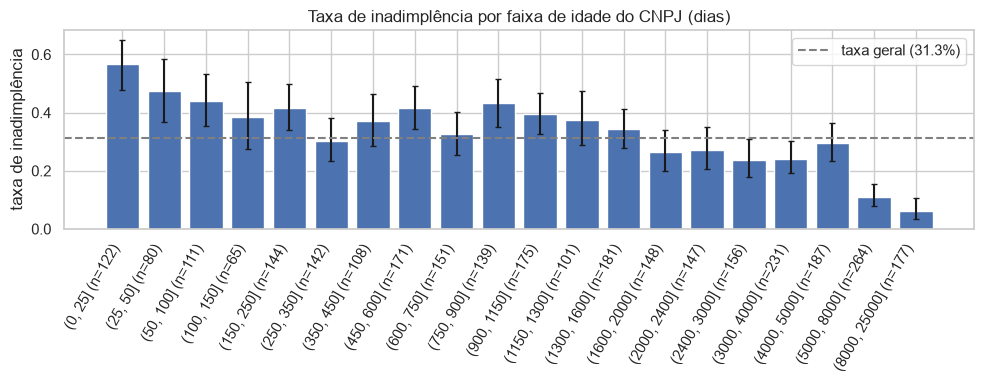

,n,inadimplentes,taxa,ic_inf,ic_sup,baixa_repr
idade_cnpj,,,,,,
"(0, 25]",122,69,0.566,0.477,0.650,False
"(25, 50]",80,38,0.475,0.369,0.583,False
"(50, 100]",111,49,0.441,0.353,0.534,False
"(100, 150]",65,25,0.385,0.276,0.506,False
"(150, 250]",144,60,0.417,0.339,0.498,False
"(250, 350]",142,43,0.303,0.233,0.383,False
"(350, 450]",108,40,0.370,0.285,0.464,False
"(450, 600]",171,71,0.415,0.344,0.490,False
"(600, 750]",151,49,0.325,0.255,0.403,False


In [4]:
def por_faixa(col):
    g = taxa_por_grupo(clientes, col)
    ordem = clientes.groupby(col)[f"{col}_ord"].first()
    return g.loc[ordem.sort_values().index]

g_idade = por_faixa("idade_cnpj")
plot_taxa(g_idade, "Taxa de inadimplência por faixa de idade do CNPJ (dias)", "taxa_idade_cnpj")
g_idade

In [5]:
acima = clientes["idade_cnpj_num"] > 2400
print(f"CNPJ > 2.400 dias: {clientes.loc[acima, 'inadimplente'].mean():.1%} (n={acima.sum()}) | "
      f"até 2.400 dias: {clientes.loc[~acima, 'inadimplente'].mean():.1%} (n={(~acima).sum()})")

CNPJ > 2.400 dias: 18.5% (n=1015) | até 2.400 dias: 37.9% (n=1985)


### 1.3 Capital social

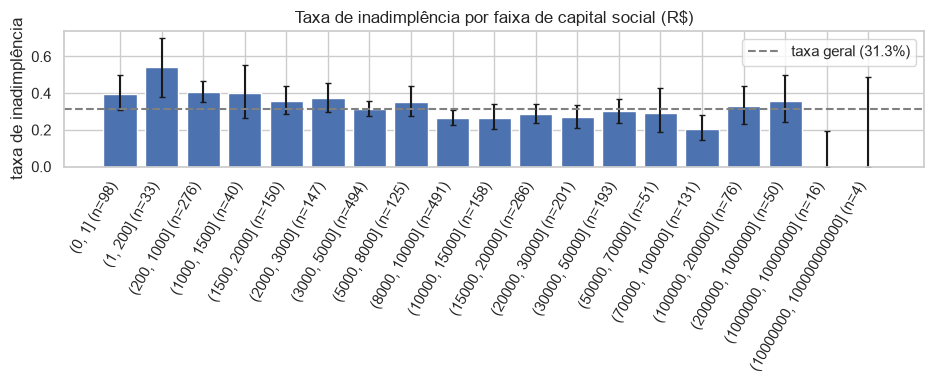

,n,inadimplentes,taxa,ic_inf,ic_sup,baixa_repr
capital_social,,,,,,
"(0, 1]",98,39,0.398,0.307,0.497,False
"(1, 200]",33,18,0.545,0.380,0.702,False
"(200, 1000]",276,113,0.409,0.353,0.468,False
"(1000, 1500]",40,16,0.400,0.263,0.554,False
"(1500, 2000]",150,54,0.360,0.288,0.439,False
"(2000, 3000]",147,55,0.374,0.300,0.455,False
"(3000, 5000]",494,156,0.316,0.276,0.358,False
"(5000, 8000]",125,44,0.352,0.274,0.439,False
"(8000, 10000]",491,130,0.265,0.228,0.306,False


In [6]:
g_cap = por_faixa("capital_social")
plot_taxa(g_cap, "Taxa de inadimplência por faixa de capital social (R$)", "taxa_capital_social")
g_cap

### 1.4 Negativações e protestos (cauda longa)

serasa_contagem_negativacoes: % zero=79.0% | p95=5 | p99=15 | máx=141 | acima do limite do IQR (> 0): 631
serasa_contagem_protestos: % zero=92.3% | p95=1 | p99=6 | máx=79 | acima do limite do IQR (> 0): 231


,n,inadimplentes,taxa,ic_inf,ic_sup,baixa_repr
faixa,,,,,,
0,2369,661,0.279,0.261,0.297,False
1-2,338,125,0.370,0.320,0.422,False
3+,293,154,0.526,0.468,0.582,False


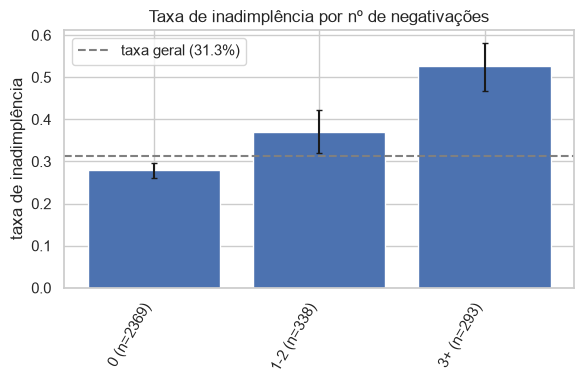

,n,inadimplentes,taxa,ic_inf,ic_sup,baixa_repr
faixa,,,,,,
0,2769,853,0.308,0.291,0.326,False
1-2,150,49,0.327,0.257,0.405,False
3+,81,38,0.469,0.364,0.577,False


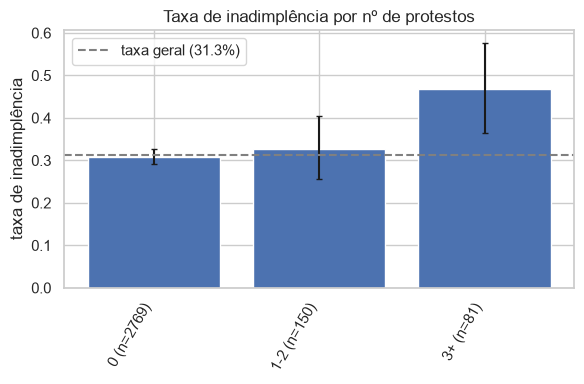

In [7]:
for col in ["serasa_contagem_negativacoes", "serasa_contagem_protestos"]:
    s = clientes[col]
    q1, q3 = s.quantile([0.25, 0.75])
    print(f"{col}: % zero={(s == 0).mean():.1%} | p95={s.quantile(.95):.0f} | p99={s.quantile(.99):.0f} | máx={s.max()} | "
          f"acima do limite do IQR (> {q3 + 1.5 * (q3 - q1):.0f}): {(s > q3 + 1.5 * (q3 - q1)).sum()}")

faixas = lambda s: pd.cut(s, [-1, 0, 2, np.inf], labels=["0", "1-2", "3+"])
for col, titulo in [("serasa_contagem_negativacoes", "negativações"), ("serasa_contagem_protestos", "protestos")]:
    g = taxa_por_grupo(clientes.assign(faixa=faixas(clientes[col])), "faixa")
    display(g)
    plot_taxa(g, f"Taxa de inadimplência por nº de {titulo}", f"taxa_{col}")

### 1.5 Correlação entre variáveis numéricas (Spearman)

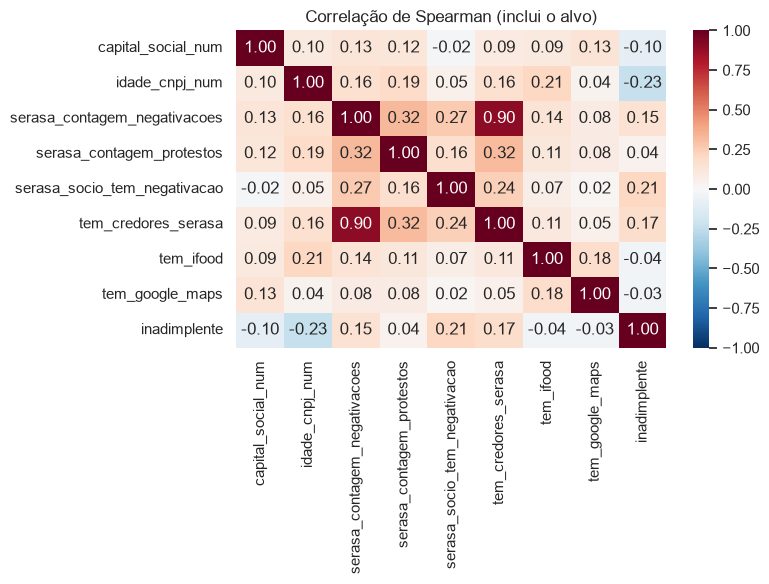

In [8]:
num = clientes[["capital_social_num", "idade_cnpj_num", "serasa_contagem_negativacoes", "serasa_contagem_protestos",
                "serasa_socio_tem_negativacao", "tem_credores_serasa", "tem_ifood", "tem_google_maps", "inadimplente"]]
plt.figure(figsize=(8, 6))
sns.heatmap(num.corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Correlação de Spearman (inclui o alvo)")
salvar("correlacao_spearman")

## 2. Variáveis categóricas e binárias
`uf` fica de fora porque é constante (todos os clientes são do CE).

,n,inadimplentes,taxa,ic_inf,ic_sup,baixa_repr
natureza_juridica,,,,,,
205-4 - Sociedade Anônima Fechada,1,1,1.000,0.207,1.000,True
206-2 - Sociedade Empresária Limitada,736,157,0.213,0.185,0.244,False
213-5 - Empresário (Individual),2249,781,0.347,0.328,0.367,False
224-0 - Sociedade Simples Limitada,2,0,0.000,0.000,0.658,True
230-5 - Empresa Individual de Responsabilidade Limitada (de Natureza Empresária),12,1,0.083,0.015,0.354,True


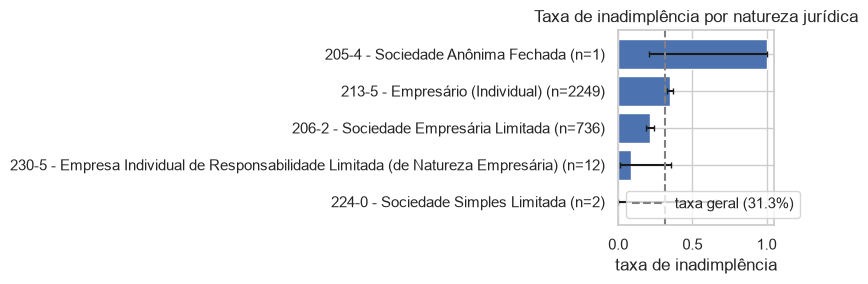

,n,inadimplentes,taxa,ic_inf,ic_sup,baixa_repr
fonte_cliente,,,,,,
Fonte 1,2055,560,0.273,0.254,0.292,False
Fonte 2,200,101,0.505,0.436,0.574,False
Fonte 3,7,2,0.286,0.082,0.641,True
Fonte 4,2,1,0.500,0.095,0.905,True
Fonte 5,736,276,0.375,0.341,0.411,False


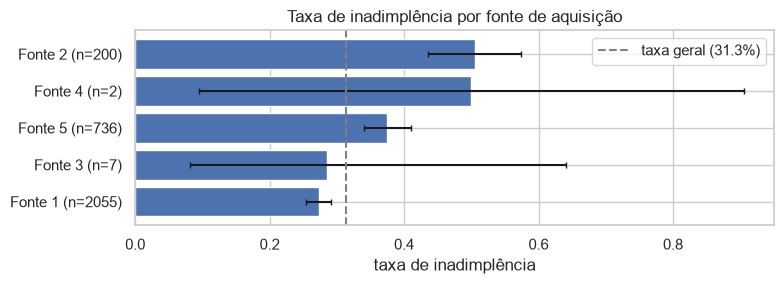

In [9]:
for col, titulo in [("natureza_juridica", "natureza jurídica"), ("fonte_cliente", "fonte de aquisição")]:
    g = taxa_por_grupo(clientes, col)
    display(g)
    plot_taxa(g, f"Taxa de inadimplência por {titulo}", f"taxa_{col}", horizontal=True, ordenar=True)

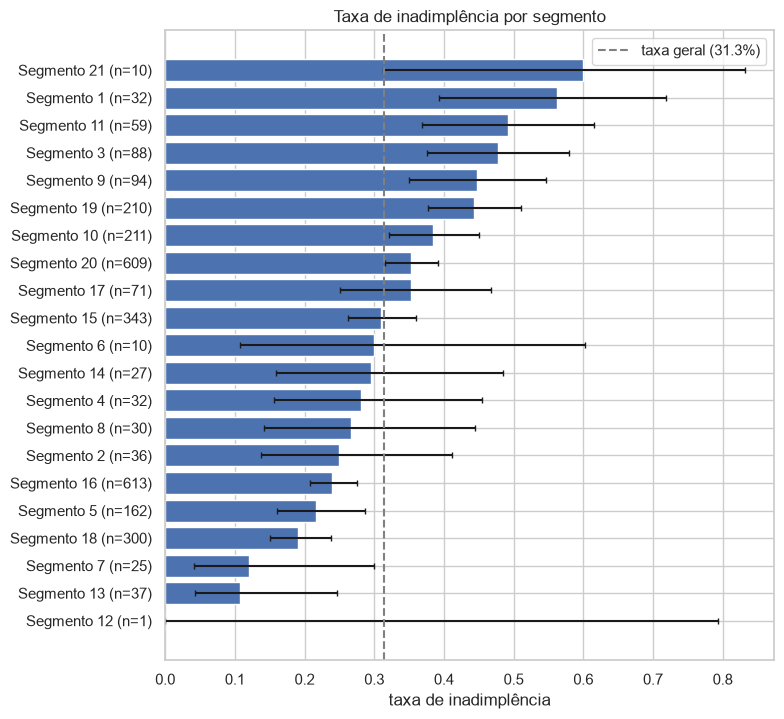

,n,inadimplentes,taxa,ic_inf,ic_sup,baixa_repr
segmento_cliente,,,,,,
Segmento 12,1,0,0.000,0.000,0.793,True
Segmento 13,37,4,0.108,0.043,0.247,False
Segmento 7,25,3,0.120,0.042,0.300,True
Segmento 18,300,57,0.190,0.150,0.238,False
Segmento 5,162,35,0.216,0.160,0.286,False
Segmento 16,613,147,0.240,0.208,0.275,False
Segmento 2,36,9,0.250,0.138,0.411,False
Segmento 8,30,8,0.267,0.142,0.444,False
Segmento 4,32,9,0.281,0.156,0.454,False


In [10]:
g_seg = taxa_por_grupo(clientes, "segmento_cliente")
plot_taxa(g_seg, "Taxa de inadimplência por segmento", "taxa_segmento", horizontal=True, ordenar=True)
g_seg.sort_values("taxa")

### 2.1 Município: Fortaleza × Região Metropolitana × interior
A lista da RM de Fortaleza tem os 19 municípios definidos pela legislação estadual (LC 18/1999 e alterações). Os nomes são comparados sem acento.

{'Fortaleza': ['FORTALEZA'], 'Interior': ['ACARAPE', 'ACARAU', 'ARACATI', 'ARACOIABA', 'BARREIRA', 'BATURITE', 'BEBERIBE', 'FORTIM', 'GUARAMIRANGA', 'ICAPUI', 'ITAICABA', 'JAGUARUANA', 'JUAZEIRO DO NORTE', 'LIMOEIRO DO NORTE', 'MAURITI', 'PACOTI', 'REDENCAO', 'SALITRE', 'SOBRAL'], 'RM (sem Fortaleza)': ['AQUIRAZ', 'CASCAVEL', 'CAUCAIA', 'CHOROZINHO', 'EUSEBIO', 'GUAIUBA', 'HORIZONTE', 'ITAITINGA', 'MARACANAU', 'MARANGUAPE', 'PACAJUS', 'PACATUBA', 'PARACURU', 'PINDORETAMA', 'SAO GONCALO DO AMARANTE', 'SAO LUIS DO CURU']}


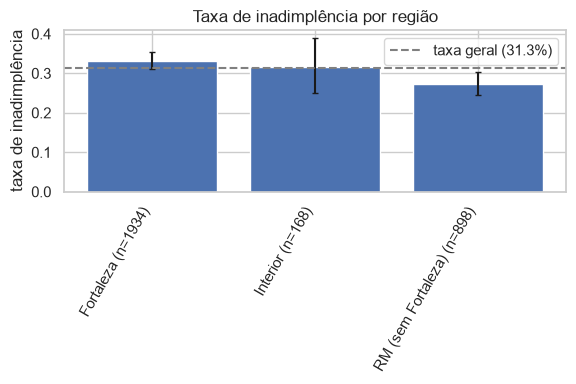

,n,inadimplentes,taxa,ic_inf,ic_sup,baixa_repr
regiao,,,,,,
Fortaleza,1934,643,0.332,0.312,0.354,False
Interior,168,53,0.315,0.250,0.389,False
RM (sem Fortaleza),898,244,0.272,0.244,0.302,False


In [11]:
RM_FORTALEZA = ["FORTALEZA", "AQUIRAZ", "CASCAVEL", "CAUCAIA", "CHOROZINHO", "EUSEBIO", "GUAIUBA", "HORIZONTE", "ITAITINGA",
                "MARACANAU", "MARANGUAPE", "PACAJUS", "PACATUBA", "PARACURU", "PARAIPABA", "PINDORETAMA",
                "SAO GONCALO DO AMARANTE", "SAO LUIS DO CURU", "TRAIRI"]
sem_acento = lambda s: unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode().upper().strip()
mun = clientes["municipio"].map(sem_acento)
clientes["regiao"] = np.select([mun == "FORTALEZA", mun.isin(RM_FORTALEZA)], ["Fortaleza", "RM (sem Fortaleza)"], "Interior")
print(clientes.groupby("regiao")["municipio"].unique().map(sorted).to_dict())
g_reg = taxa_por_grupo(clientes, "regiao")
plot_taxa(g_reg, "Taxa de inadimplência por região", "taxa_regiao")
g_reg

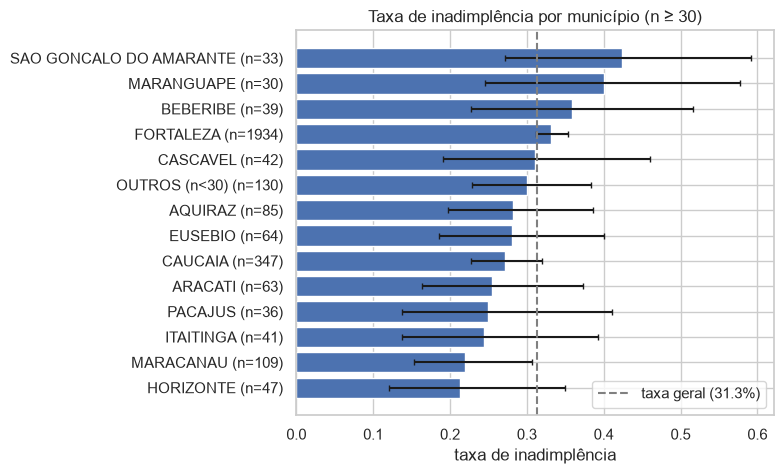

,n,inadimplentes,taxa,ic_inf,ic_sup,baixa_repr
mun,,,,,,
HORIZONTE,47,10,0.213,0.120,0.349,False
MARACANAU,109,24,0.220,0.153,0.307,False
ITAITINGA,41,10,0.244,0.138,0.393,False
PACAJUS,36,9,0.250,0.138,0.411,False
ARACATI,63,16,0.254,0.163,0.373,False
CAUCAIA,347,94,0.271,0.227,0.320,False
EUSEBIO,64,18,0.281,0.186,0.401,False
AQUIRAZ,85,24,0.282,0.198,0.386,False
OUTROS (n<30),130,39,0.300,0.228,0.384,False


In [12]:
freq = clientes["municipio"].value_counts()
g_mun = taxa_por_grupo(clientes.assign(mun=clientes["municipio"].where(clientes["municipio"].map(freq) >= 30, "OUTROS (n<30)")), "mun")
plot_taxa(g_mun, "Taxa de inadimplência por município (n ≥ 30)", "taxa_municipio", horizontal=True, ordenar=True)
g_mun.sort_values("taxa")

### 2.2 Variáveis binárias

In [13]:
BINARIAS = ["serasa_socio_tem_negativacao", "tem_credores_serasa", "tem_ifood", "tem_google_maps", "google_maps_tem_website"]
linhas = []
for col in BINARIAS:
    g = taxa_por_grupo(clientes, col)
    linhas.append({"variável": col, "n_com": g.loc[1, "n"], "taxa_com": g.loc[1, "taxa"], "n_sem": g.loc[0, "n"],
                   "taxa_sem": g.loc[0, "taxa"], "diferença_pp": round(100 * (g.loc[1, "taxa"] - g.loc[0, "taxa"]), 1)})
pd.DataFrame(linhas).set_index("variável")

,n_com,taxa_com,n_sem,taxa_sem,diferença_pp
variável,,,,,
serasa_socio_tem_negativacao,1427,0.415,1573,0.221,19.4
tem_credores_serasa,534,0.485,2466,0.276,20.9
tem_ifood,363,0.267,2637,0.320,-5.3
tem_google_maps,208,0.260,2792,0.317,-5.7
google_maps_tem_website,208,0.260,2792,0.317,-5.7


`google_maps_tem_website` é igual a `tem_google_maps`: todos os 208 clientes do Maps têm site. É uma variável redundante.

### 2.3 Associação com o alvo (qui-quadrado e V de Cramér)
O V de Cramér tende a crescer com o número de categorias pequenas. Em variáveis de alta cardinalidade, compare com cautela.

In [14]:
CATEG = ["natureza_juridica", "fonte_cliente", "segmento_cliente", "municipio", "regiao", "ifood_faixa_preco"] + BINARIAS
pd.DataFrame({c: cramer_v(clientes, c) for c in CATEG}).T.sort_values("v_cramer", ascending=False)

,categorias,chi2,p_valor,v_cramer
serasa_socio_tem_negativacao,2.0,129.5,5.335223e-30,0.208
segmento_cliente,21.0,123.7,5.777804e-17,0.203
tem_credores_serasa,2.0,88.0,6.445050e-21,0.171
fonte_cliente,5.0,63.4,5.519442e-13,0.145
natureza_juridica,5.0,52.3,1.188116e-10,0.132
municipio,36.0,51.7,3.412961e-02,0.131
regiao,3.0,10.5,5.181760e-03,0.059
ifood_faixa_preco,6.0,9.1,1.057382e-01,0.055
tem_ifood,2.0,3.8,4.999267e-02,0.036
tem_google_maps,2.0,2.7,9.815883e-02,0.030


## 3. CNAE e credores da Serasa
### 3.1 Hierarquia do CNAE
Divisão = 2 dígitos, grupo = 3 dígitos, classe = 5 dígitos + dígito verificador, subclasse = código completo. Os códigos foram anonimizados (não são atividades reais), mas a hierarquia foi mantida.

In [15]:
cod = clientes["cnae_codigo"]
clientes["cnae_divisao"] = cod.str[:2]
clientes["cnae_grupo"] = cod.str[:4]
clientes["cnae_classe"] = cod.str[:7]
clientes["cnae_subclasse"] = cod
NIVEIS = ["cnae_divisao", "cnae_grupo", "cnae_classe", "cnae_subclasse"]
resumo = pd.DataFrame({n: {"categorias": clientes[n].nunique(),
                           "categorias_n≥30": (clientes[n].value_counts() >= 30).sum(),
                           "% clientes em categorias n≥30": round(100 * clientes[n].map(clientes[n].value_counts()).ge(30).mean(), 1)}
                       for n in NIVEIS}).T
resumo.join(pd.DataFrame({n: cramer_v(clientes, n) for n in NIVEIS}).T[["p_valor", "v_cramer"]])

,categorias,categorias_n≥30,% clientes em categorias n≥30,p_valor,v_cramer
cnae_divisao,39.0,3.0,92.3,1.763865e-07,0.183
cnae_grupo,83.0,10.0,90.2,1.692919e-08,0.240
cnae_classe,111.0,11.0,86.9,2.416436e-10,0.276
cnae_subclasse,153.0,15.0,83.3,7.220068e-11,0.312


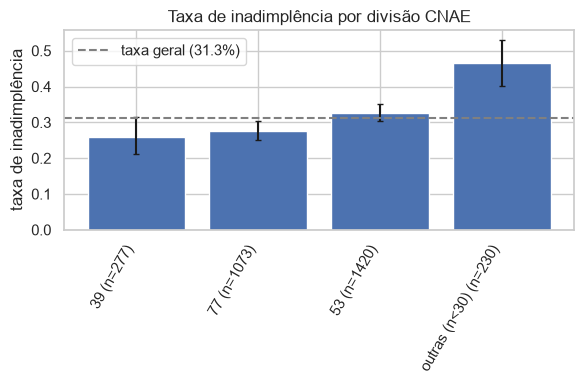

,n,inadimplentes,taxa,ic_inf,ic_sup,baixa_repr
div,,,,,,
39,277,72,0.260,0.212,0.315,False
53,1420,464,0.327,0.303,0.352,False
77,1073,297,0.277,0.251,0.304,False
outras (n<30),230,107,0.465,0.402,0.530,False


In [16]:
freq = clientes["cnae_divisao"].value_counts()
g_div = taxa_por_grupo(clientes.assign(div=clientes["cnae_divisao"].where(clientes["cnae_divisao"].map(freq) >= 30, "outras (n<30)")), "div")
plot_taxa(g_div, "Taxa de inadimplência por divisão CNAE", "taxa_cnae_divisao", ordenar=True)
g_div

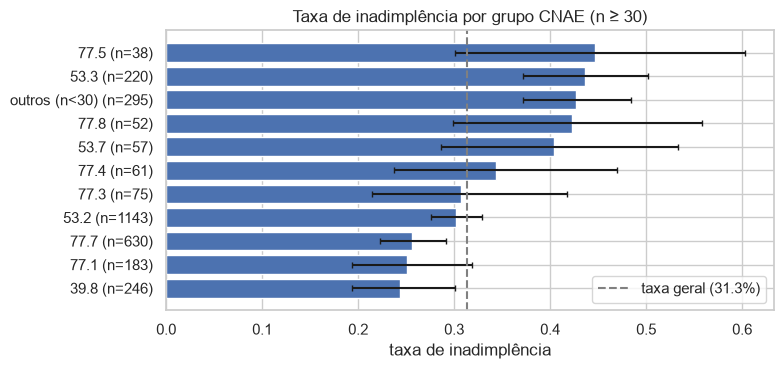

,n,inadimplentes,taxa,ic_inf,ic_sup,baixa_repr
grp,,,,,,
39.8,246,60,0.244,0.194,0.301,False
77.1,183,46,0.251,0.194,0.319,False
77.7,630,161,0.256,0.223,0.291,False
53.2,1143,345,0.302,0.276,0.329,False
77.3,75,23,0.307,0.214,0.418,False
77.4,61,21,0.344,0.237,0.470,False
53.7,57,23,0.404,0.286,0.533,False
77.8,52,22,0.423,0.299,0.558,False
outros (n<30),295,126,0.427,0.372,0.484,False


In [17]:
freq = clientes["cnae_grupo"].value_counts()
g_grp = taxa_por_grupo(clientes.assign(grp=clientes["cnae_grupo"].where(clientes["cnae_grupo"].map(freq) >= 30, "outros (n<30)")), "grp")
plot_taxa(g_grp, "Taxa de inadimplência por grupo CNAE (n ≥ 30)", "taxa_cnae_grupo", horizontal=True, ordenar=True)
g_grp.sort_values("taxa")

### 3.2 Credores na Serasa
`serasa_credores` é nulo quando o cliente não deve a ninguém. Quando existe, é uma lista de segmentos separada por vírgula. A Praso diz "até 5", mas há casos com mais itens.

{0: 2466, 1: 324, 2: 99, 3: 70, 4: 29, 5: 7, 6: 3, 7: 2}


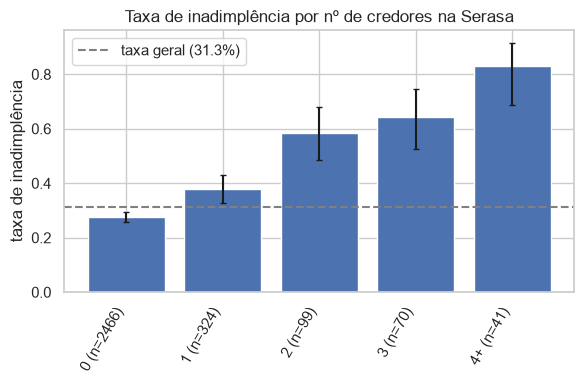

,n,inadimplentes,taxa,ic_inf,ic_sup,baixa_repr
n_cred,,,,,,
0,2466,681,0.276,0.259,0.294,False
1,324,122,0.377,0.326,0.430,False
2,99,58,0.586,0.487,0.678,False
3,70,45,0.643,0.526,0.745,False
4+,41,34,0.829,0.687,0.915,False


In [18]:
lista = clientes["serasa_credores"].fillna("").str.split(",").map(lambda l: [x.strip() for x in l if x.strip()])
clientes["n_credores"] = lista.str.len()
clientes["n_segmentos_credores"] = lista.map(lambda l: len(set(l)))
print(clientes["n_credores"].value_counts().sort_index().to_dict())
g_ncred = taxa_por_grupo(clientes.assign(n_cred=clientes["n_credores"].clip(upper=4).astype(str).replace("4", "4+")), "n_cred")
plot_taxa(g_ncred, "Taxa de inadimplência por nº de credores na Serasa", "taxa_n_credores")
g_ncred

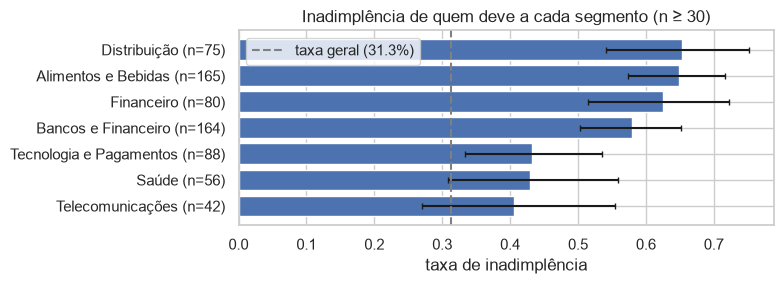

,n,inadimplentes,taxa,ic_inf,ic_sup,baixa_repr
segmento_credor,,,,,,
Alimentos e Bebidas,165,107,0.648,0.573,0.717,False
Bancos e Financeiro,164,95,0.579,0.503,0.652,False
Tecnologia e Pagamentos,88,38,0.432,0.333,0.536,False
Financeiro,80,50,0.625,0.515,0.723,False
Distribuição,75,49,0.653,0.541,0.751,False
Saúde,56,24,0.429,0.308,0.559,False
Telecomunicações,42,17,0.405,0.270,0.555,False
Diversos,28,15,0.536,0.358,0.705,True
Comércio,24,15,0.625,0.427,0.788,True


In [19]:
explodido = clientes.assign(segmento_credor=lista).explode("segmento_credor").dropna(subset=["segmento_credor"])
explodido = explodido.drop_duplicates(["id_cliente", "segmento_credor"])
g_segcred = taxa_por_grupo(explodido, "segmento_credor")
plot_taxa(g_segcred[g_segcred["n"] >= 30], "Inadimplência de quem deve a cada segmento (n ≥ 30)", "taxa_segmento_credor",
          horizontal=True, ordenar=True)
g_segcred.sort_values("n", ascending=False)

In [20]:
rho = stats.spearmanr(clientes["n_credores"], clientes["serasa_contagem_negativacoes"])[0]
print(f"Spearman nº credores × negativações: {rho:.2f}")

Spearman nº credores × negativações: 0.90


Entre quem tem credores, todos os segmentos com n ≥ 30 ficam acima da taxa geral. Ter credor já indica mais risco, e a diferença entre segmentos pesa menos que a quantidade.

## 4. Histórico de pedidos (exploratório; as features formais são da KAN-7)

In [21]:
ag = pedidos.groupby("id_cliente").agg(n_pedidos=("id_pedido", "size"), valor_medio=("valor_num", "mean"),
                                        prop_atraso=("atrasou", "mean"), atraso_max=("atraso_num", "max"),
                                        atraso_medio=("atraso_num", "mean"), primeiro_pedido=("data_entrega", "min"))
cp = clientes.merge(ag, on="id_cliente")
clientes["tem_pedidos"] = clientes["id_cliente"].isin(pedidos["id_cliente"]).astype(int)
display(taxa_por_grupo(clientes, "tem_pedidos"))
print("pedidos por cliente:", ag["n_pedidos"].value_counts().sort_index().to_dict())

,n,inadimplentes,taxa,ic_inf,ic_sup,baixa_repr
tem_pedidos,,,,,,
0,2336,802,0.343,0.324,0.363,False
1,664,138,0.208,0.179,0.240,False


pedidos por cliente: {1: 2, 2: 13, 3: 649}


649 dos 664 clientes com pedidos têm exatamente 3 pedidos (provavelmente um recorte da Praso). A quantidade de pedidos não diferencia ninguém, então o sinal está no atraso e no valor.

,n,inadimplentes,taxa,ic_inf,ic_sup,baixa_repr
atraso_max_faixa,,,,,,
0,70,5,0.071,0.031,0.157,False
1-4,410,63,0.154,0.122,0.192,False
5-10,109,38,0.349,0.266,0.442,False
>10,75,32,0.427,0.321,0.539,False


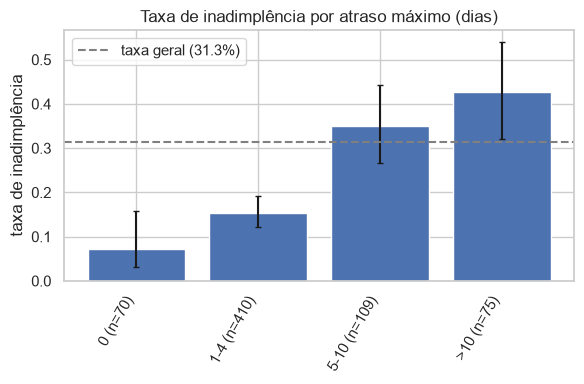

,n,inadimplentes,taxa,ic_inf,ic_sup,baixa_repr
prop_atraso_faixa,,,,,,
0%,70,5,0.071,0.031,0.157,False
"(0, 50%]",92,8,0.087,0.045,0.162,False
"(50%, 100%]",502,125,0.249,0.213,0.289,False


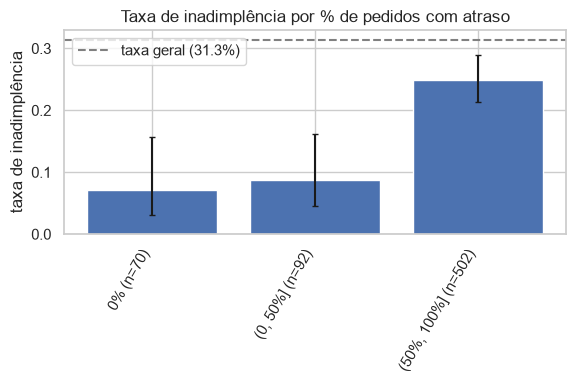

,n,inadimplentes,taxa,ic_inf,ic_sup,baixa_repr
valor_medio_faixa,,,,,,
"(249.999, 416.667]",526,121,0.230,0.196,0.268,False
"(416.667, 2000.0]",138,17,0.123,0.078,0.188,False


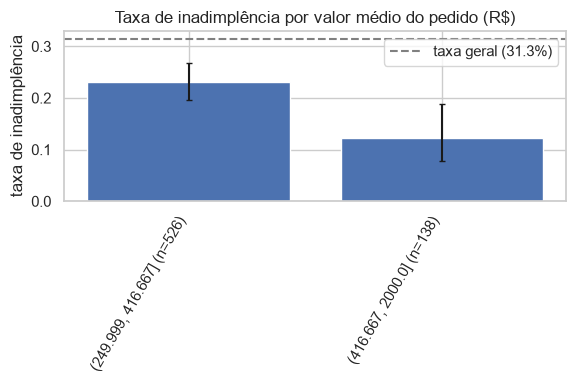

In [22]:
cp["atraso_max_faixa"] = pd.cut(cp["atraso_max"], [-1, 0, 4, 10, np.inf], labels=["0", "1-4", "5-10", ">10"])
cp["prop_atraso_faixa"] = pd.cut(cp["prop_atraso"], [-0.01, 0, 0.5, 1], labels=["0%", "(0, 50%]", "(50%, 100%]"])
cp["valor_medio_faixa"] = pd.qcut(cp["valor_medio"], 3, duplicates="drop")
for col, titulo in [("atraso_max_faixa", "atraso máximo (dias)"), ("prop_atraso_faixa", "% de pedidos com atraso"),
                    ("valor_medio_faixa", "valor médio do pedido (R$)")]:
    g = taxa_por_grupo(cp, col)
    display(g)
    plot_taxa(g, f"Taxa de inadimplência por {titulo}", f"taxa_{col}")

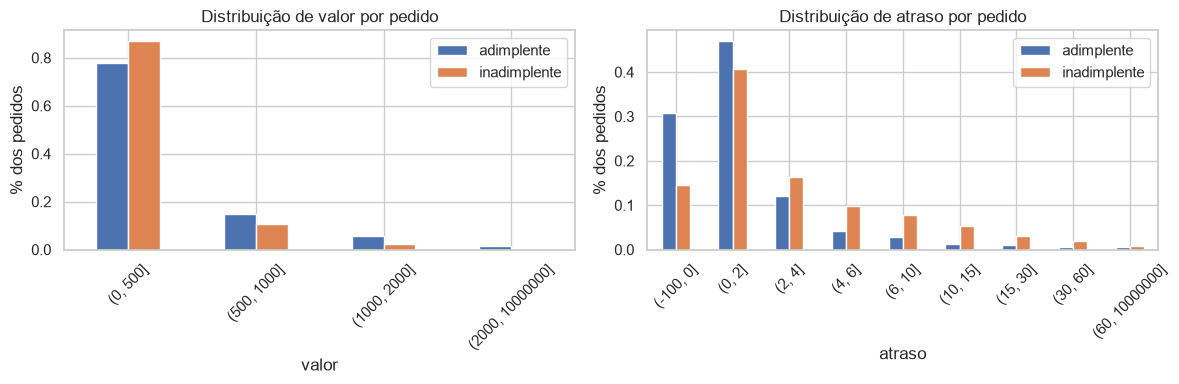

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["valor", "atraso"]):
    t = pd.crosstab(pedidos[f"{col}_ord"], pedidos["id_cliente"].map(clientes.set_index("id_cliente")["inadimplente"]), normalize="columns")
    t.index = pedidos.groupby(f"{col}_ord")[col].first().loc[t.index]
    t.plot.bar(ax=ax, rot=45)
    ax.set_title(f"Distribuição de {col} por pedido"); ax.set_ylabel("% dos pedidos"); ax.legend(["adimplente", "inadimplente"])
salvar("distribuicao_valor_atraso")

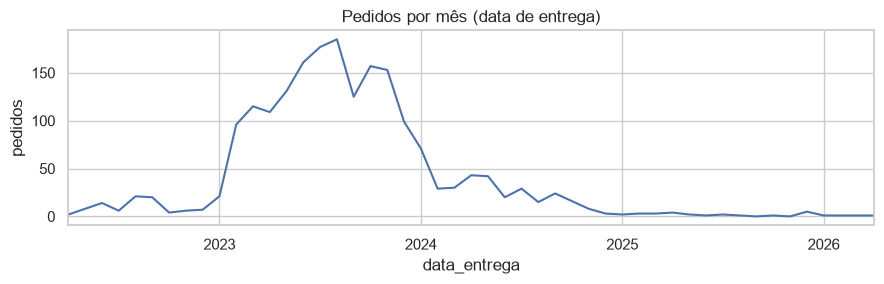

,n,inadimplentes,taxa,ic_inf,ic_sup,baixa_repr
coorte,,,,,,
2022,45,1,0.022,0.004,0.116,False
2023,573,127,0.222,0.190,0.257,False
2024,46,10,0.217,0.123,0.356,False


In [24]:
mensal = pedidos.set_index("data_entrega").resample("ME").size()
ax = mensal.plot(figsize=(9, 3), title="Pedidos por mês (data de entrega)")
ax.set_ylabel("pedidos")
salvar("pedidos_por_mes")
g_coorte = taxa_por_grupo(cp.assign(coorte=cp["primeiro_pedido"].dt.year), "coorte")
g_coorte

### Cuidados para a KAN-7/KAN-8 (vazamento)
- Não sabemos **em que data** a inadimplência foi observada. Pedidos e atrasos posteriores ao evento podem estar "contando" o próprio alvo: um atraso enorme pode *ser* a inadimplência.
- 77% dos pedidos são de 2023, e a coorte de 2022 tem taxa muito baixa. Clientes antigos tiveram mais tempo para se mostrar bons pagadores, o que é um viés de sobrevivência e tempo de exposição.
- Para mitigar: definir uma data de corte por cliente (ex.: a data do último pedido) e calcular as features **só com os pedidos anteriores** a ela; excluir o atraso do último pedido; comparar o AUC com e sem as variáveis de atraso para checar se o ganho é plausível.

## 5. Conclusões

Taxa geral de inadimplência: **31,3%** (940 de 3.000).

### 5.1 Hipóteses × dados

| Hipótese | Veredito | Evidência |
|---|---|---|
| H1 — CNPJ novo, mais risco | **Confirmada** | 56,6% em (0, 25] dias contra 6,2% acima de 8.000 dias; acima de 2.400 dias: 18,5% contra 37,9% (como a Praso indicou). A curva não é monotônica no meio, e a maior queda é acima de 5.000 dias (11,0%). Spearman −0,23, o sinal mais forte entre as contínuas. |
| H2 — capital social maior, menos risco (fraco) | **Confirmada (fraca)** | Mediana 6.500 (inad.) contra 9.000 (adimp.); Spearman −0,10. As faixas até R$ 1.000 ficam perto de 40%, e de R$ 8 mil a R$ 30 mil ficam entre 26% e 29%. Não é monotônico: de R$ 100 mil a R$ 1 mi a taxa volta a 33–36%. |
| H3 — Empresário Individual > LTDA | **Confirmada** | 34,7% (n=2.249) contra 21,3% (n=736). As outras naturezas têm n < 30. |
| H4 — negativações/protestos aumentam o risco; protesto pesa mais | **Parcial** | Negativações 0 / 1–2 / 3+: 27,9% / 37,0% / 52,6%. Protestos 0 / 1–2 / 3+: 30,8% / 32,7% / 46,9%; a faixa 1–2 não se distingue de 0 (ICs se sobrepõem). O protesto é um sinal **mais fraco** que a negativação (Spearman 0,04 contra 0,15), o que refuta a segunda parte. |
| H5 — sócio negativado, mais risco | **Confirmada** | 41,5% contra 22,1% (+19,4 p.p.), maior V de Cramér entre as categóricas (0,21). A interação com a natureza jurídica não foi testada. |
| H6 — mais credores, mais risco; credor comercial/financeiro pesa mais | **Confirmada** | 0 / 1 / 2 / 3 / 4+ credores: 27,6% / 37,7% / 58,6% / 64,3% / 82,9%. Por segmento (n ≥ 30): Distribuição 65,3%, Alimentos e Bebidas 64,8%, Financeiro 62,5% e Bancos 57,9%, contra Telecomunicações 40,5%, Saúde 42,9% e Tecnologia e Pagamentos 43,2%. |
| H7 — estar no iFood/Maps, menos risco | **Inconclusiva (fraca)** | A direção bate: iFood 26,7% contra 32,0% (p = 0,05) e Maps 26,0% contra 31,7% (p = 0,10). O efeito é pequeno, e só 12% e 7% dos clientes estão nas plataformas. |
| H8 — mais avaliações/site, menos risco; nota baixa, mais risco | **Parcial** | Nº de avaliações no Maps: mediana 40 (inad.) contra 150 (adimp.), p = 0,003 (n = 208). Nota do Maps: só 34 clientes, inconclusiva. Avaliações no iFood: p = 0,87. `google_maps_tem_website` é idêntico a `tem_google_maps`, então não dá para testar o site. |
| H9 — faixa de preço alta no iFood, menos risco | **Inconclusiva** | Qui-quadrado com p = 0,11, e as faixas $$ a $$$$$ têm n < 35. |
| H10 — segmento/CNAE diferenciam; níveis amplos do CNAE bastam | **Confirmada / parcial** | Segmentos com n ≥ 30 vão de 10,8% a 56,2% (V = 0,20). No CNAE, só 3 divisões têm n ≥ 30, e as divisões raras juntas somam 46,5%. No nível de grupo há 10 grupos com n ≥ 30, de 24,4% a 44,7%. O V cresce com a granularidade (0,18 → 0,31), em parte por inflação de categorias pequenas: o **grupo** parece o melhor equilíbrio. |
| H11 — fontes diferem | **Confirmada** | Fonte 2: 50,5%, Fonte 5: 37,5%, Fonte 1: 27,3%. Fontes 3 e 4 têm n = 7 e 2. |
| H12 — interior, mais risco | **Refutada** | Interior 31,5% (IC 25–39%, n = 168), Fortaleza 33,2%, RM sem Fortaleza 27,2%. A RM fica *abaixo* da capital. |
| H13 — mais pedidos, menos risco; pedido grande fora do padrão, mais risco | **Inconclusiva** | 649 de 664 clientes têm exatamente 3 pedidos, então não dá para testar a frequência. Ter histórico vem com menos risco (20,8% contra 34,3%), e valor médio mais alto também (12,3% contra 23,0%). Pedido "fora do padrão do cliente" não foi testado. |
| H14 — atraso histórico, mais risco | **Confirmada (com ressalva)** | Atraso máximo 0 / 1–4 / 5–10 / >10 dias: 7,1% / 15,4% / 34,9% / 42,7%. Mais de 50% dos pedidos atrasados: 24,9%, contra 7,1% sem atraso. Pode haver vazamento (ver seção 4). |

### 5.2 Variáveis mais promissoras (modelo de aplicação)
1. **Idade do CNPJ**, a mais forte entre as contínuas.
2. **Serasa**: sócio negativado, nº de credores e segmentos dos credores, e negativações. O **nº de credores e as negativações são quase redundantes** (Spearman 0,90).
3. **Segmento do cliente** e **CNAE no nível de grupo**.
4. **Fonte de aquisição** e **natureza jurídica**.
5. Capital social (sinal fraco e não linear).

Sinal fraco ou ausente: presença e reputação no iFood/Maps, faixa de preço, região e município. `uf` é constante e `google_maps_tem_website` é redundante; as duas podem ser descartadas.

### 5.3 Recomendações
- **KAN-5 (features):**
  - usar `idade_cnpj_ord`/`_num` (testar log) e uma flag para CNPJ com ≤ 100 dias;
  - discretizar negativações em 0 / 1–2 / 3+ e transformar protestos em binário (0 contra ≥ 1);
  - criar `n_credores` (teto em 4) e flags por grupo de segmento de credor (financeiro, alimentos/distribuição, serviços), escolhendo entre `n_credores` e negativações ou testando as duas;
  - agrupar categorias raras (n < 30) em "outros" para fonte (3 e 4), natureza jurídica, segmento e CNAE, e usar o CNAE no nível de grupo;
  - descartar `uf` e `google_maps_tem_website`.
- **KAN-6 (modelo de aplicação):** split estratificado; qualquer *target encoding* (segmento, CNAE) só dentro dos folds da validação cruzada. A regressão logística deve se beneficiar das faixas acima, porque várias relações não são lineares (idade, capital).
- **KAN-7/KAN-8 (comportamental):**
  - o número de pedidos não serve como feature (quase todos têm 3);
  - o sinal está no atraso e no valor;
  - definir uma data de corte e usar só pedidos anteriores a ela;
  - comparar o AUC com e sem as variáveis de atraso;
  - considerar o viés de coorte (2022: 2,2%, com n = 45).
- **Comparações múltiplas:** foram feitos muitos testes. Considere como evidência robusta os efeitos com p bem abaixo de 0,006 (Bonferroni para 8 testes) e ICs que não se sobrepõem.
